In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

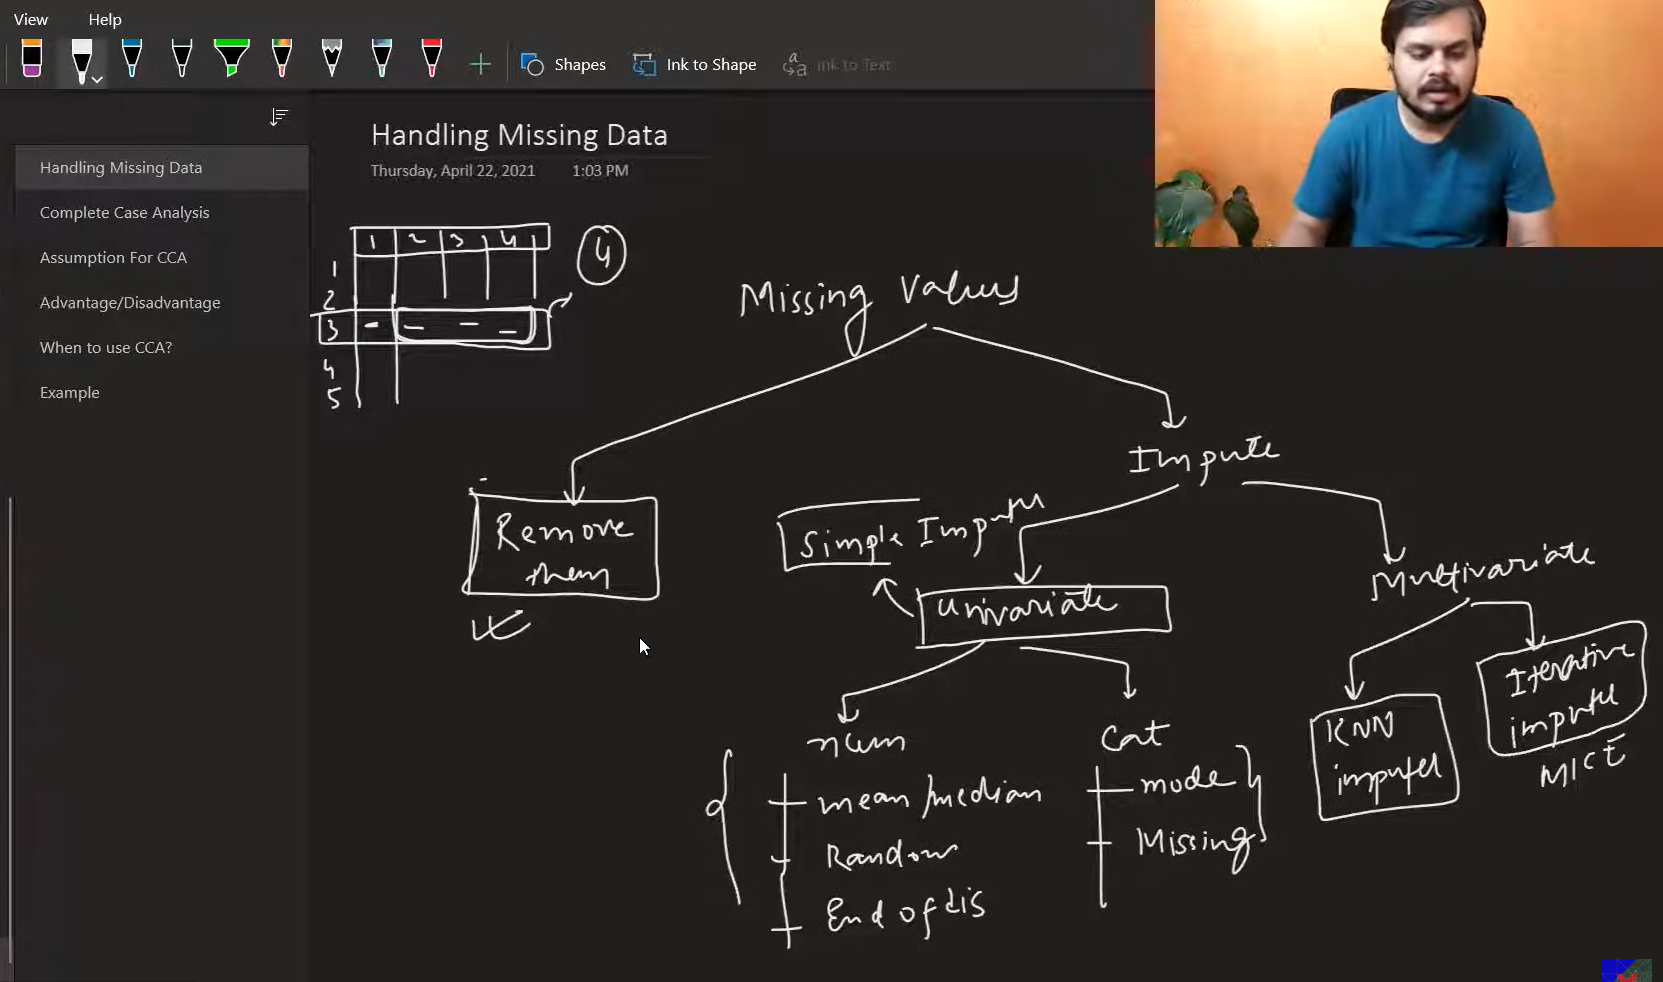

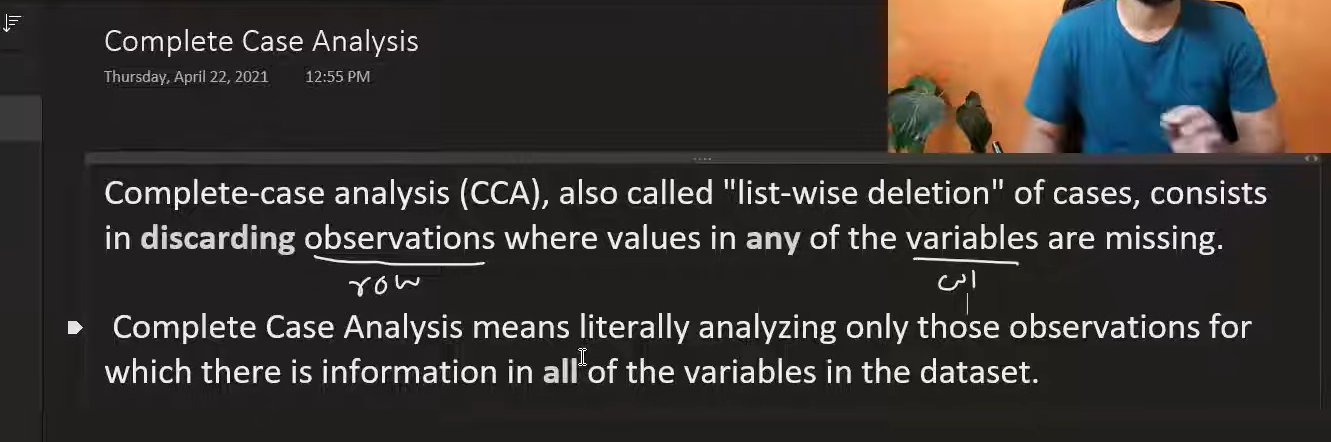

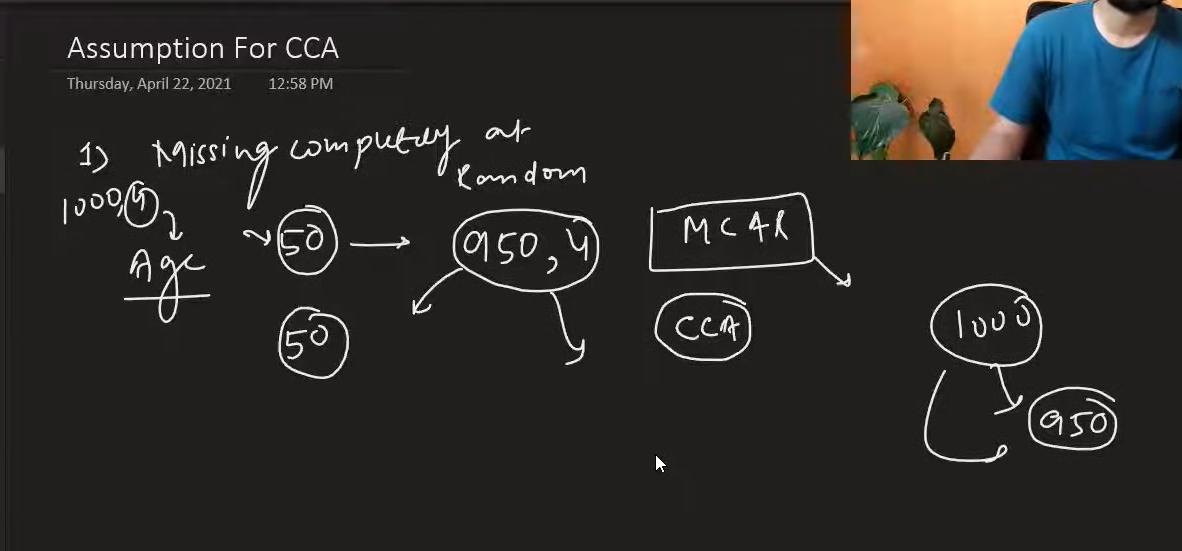

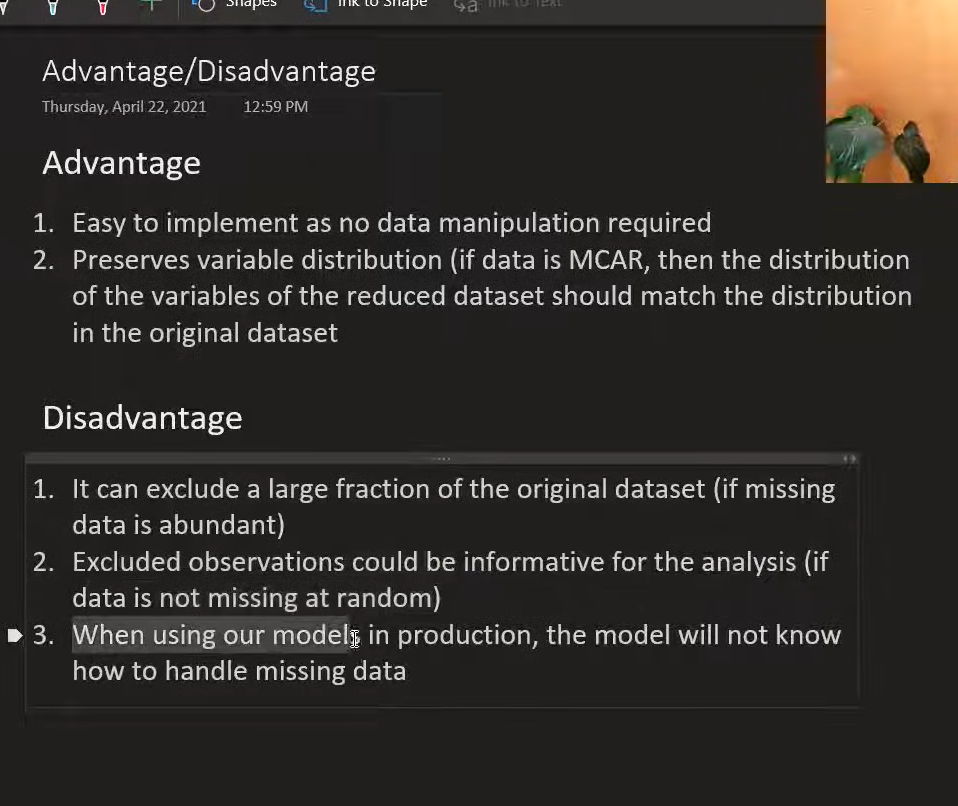

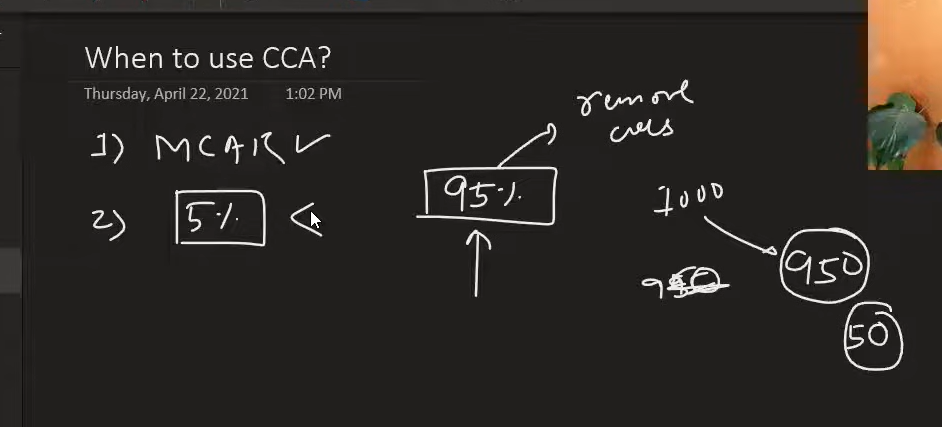

In [2]:
df = pd.read_csv('data_science_job.csv')

In [3]:
df.sample(7)

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,training_hours,target
1278,13010,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,6.0,10/49,Funded Startup,19.0,0.0
8744,2214,city_16,0.910,Male,Has relevent experience,no_enrollment,Graduate,STEM,20.0,5000-9999,Pvt Ltd,89.0,0.0
14906,12419,city_16,0.910,Male,No relevent experience,Full time course,High School,NaN,4.0,<10,Pvt Ltd,6.0,0.0
15475,29576,city_160,0.920,Male,No relevent experience,Part time course,Graduate,STEM,14.0,10000+,Public Sector,50.0,0.0
19085,3022,city_21,0.624,Male,Has relevent experience,no_enrollment,Graduate,STEM,3.0,50-99,Pvt Ltd,107.0,0.0
3652,10784,city_16,0.910,Male,Has relevent experience,no_enrollment,Graduate,STEM,20.0,NaN,Pvt Ltd,7.0,0.0
2805,28688,city_75,0.939,Male,Has relevent experience,no_enrollment,Graduate,STEM,13.0,500-999,Pvt Ltd,116.0,0.0


In [4]:
df.isnull().mean()*100

enrollee_id                0.000000
city                       0.000000
city_development_index     2.500261
gender                    23.530640
relevent_experience        0.000000
enrolled_university        2.014824
education_level            2.401086
major_discipline          14.683161
experience                 0.339284
company_size              30.994885
company_type              32.049274
training_hours             3.998330
target                     0.000000
dtype: float64

In [5]:
df.shape

(19158, 13)

In [6]:
cols = [var for var in df.columns if df[var].isnull().mean() < 0.05 and df[var].isnull().mean() > 0] # CCA on cols where null values are < 5%

cols

['city_development_index',
 'enrolled_university',
 'education_level',
 'experience',
 'training_hours']

In [7]:
df[cols].sample(5)

,city_development_index,enrolled_university,education_level,experience,training_hours
7444,0.926,Full time course,Graduate,0.0,61.0
3491,0.910,no_enrollment,Masters,20.0,28.0
11727,0.698,Full time course,High School,4.0,54.0
11371,NaN,no_enrollment,Phd,20.0,164.0
13782,NaN,no_enrollment,Graduate,1.0,37.0


In [8]:
df['education_level'].value_counts()

education_level
Graduate          11598
Masters            4361
High School        2017
Phd                 414
Primary School      308
Name: count, dtype: int64

In [9]:
len(df[cols].dropna()) / len(df)

0.8968577095730244

In [10]:
new_df = df[cols].dropna()
df.shape, new_df.shape

((19158, 13), (17182, 5))

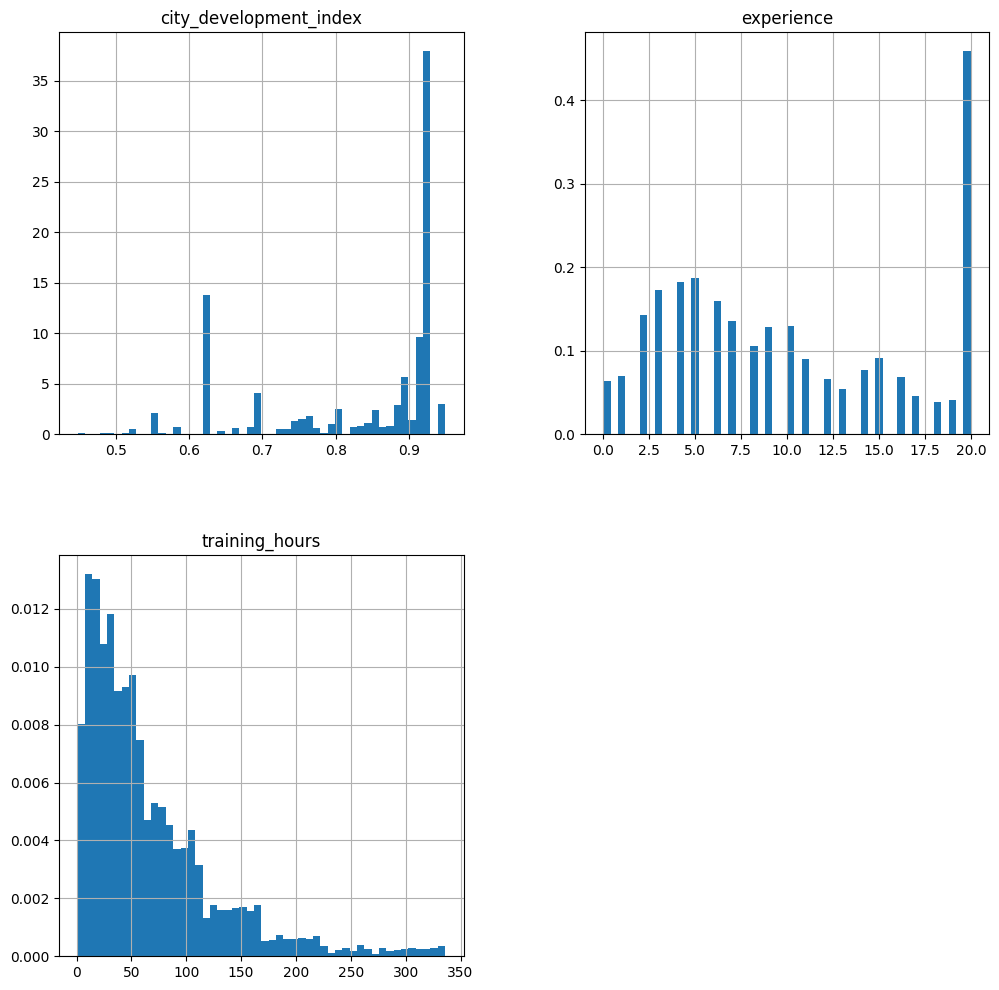

In [11]:
new_df.hist(bins=50, density=True, figsize=(12, 12))
plt.show()

<Axes: >

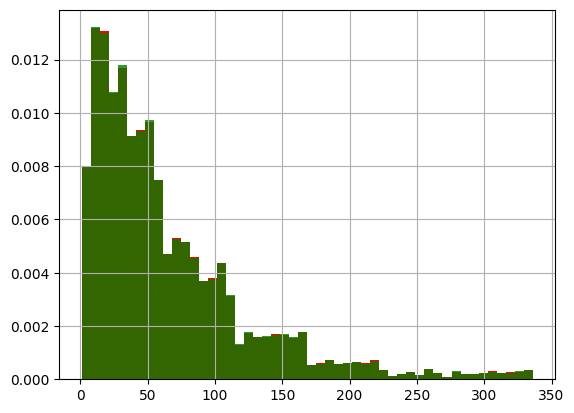

In [12]:
fig = plt.figure()
ax = fig.add_subplot(111)

# original data
df['training_hours'].hist(bins=50, ax=ax, density=True, color='red')

# data after cca, the argument alpha makes the color transparent, so we can
# see the overlay of the 2 distributions
new_df['training_hours'].hist(bins=50, ax=ax, color='green', density=True, alpha=0.8)

<Axes: ylabel='Density'>

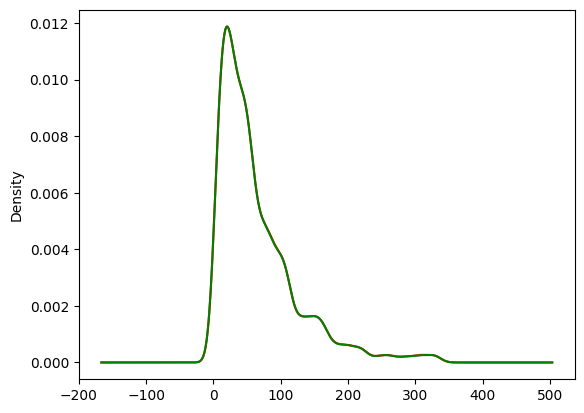

In [13]:
fig = plt.figure()
ax = fig.add_subplot(111)

# original data
df['training_hours'].plot.density(color='red')

# data after cca
new_df['training_hours'].plot.density(color='green')

<Axes: >

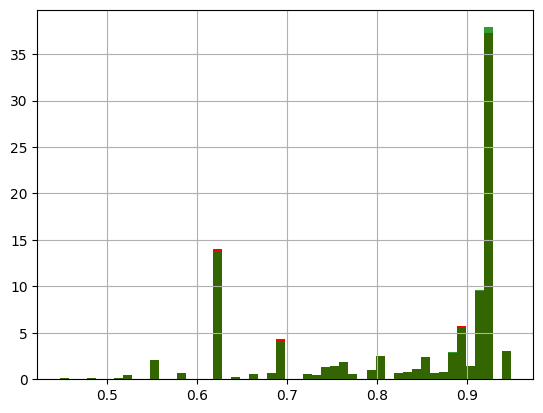

In [14]:
fig = plt.figure()
ax = fig.add_subplot(111)

# original data
df['city_development_index'].hist(bins=50, ax=ax, density=True, color='red')

# data after cca, the argument alpha makes the color transparent, so we can
# see the overlay of the 2 distributions
new_df['city_development_index'].hist(bins=50, ax=ax, color='green', density=True, alpha=0.8)

<Axes: ylabel='Density'>

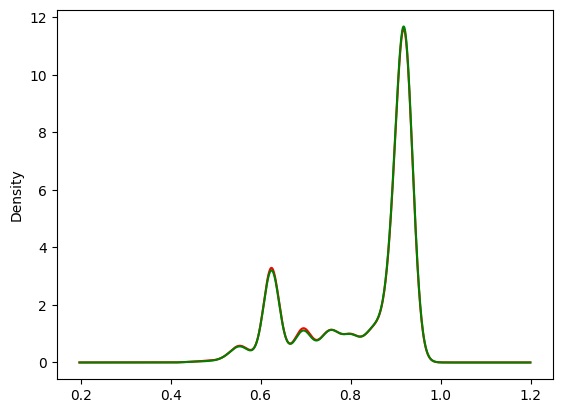

In [15]:
fig = plt.figure()
ax = fig.add_subplot(111)

# original data
df['city_development_index'].plot.density(color='red')

# data after cca
new_df['city_development_index'].plot.density(color='green')

<Axes: >

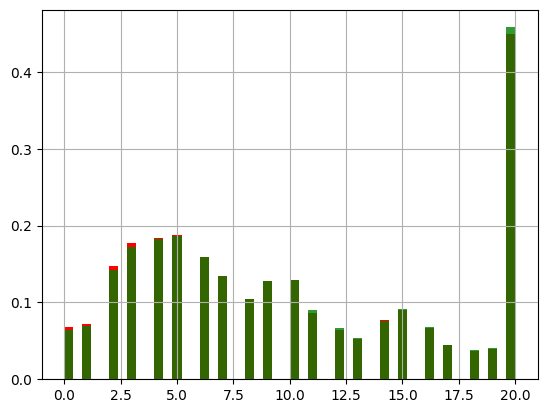

In [16]:
fig = plt.figure()
ax = fig.add_subplot(111)

# original data
df['experience'].hist(bins=50, ax=ax, density=True, color='red')

# data after cca, the argument alpha makes the color transparent, so we can
# see the overlay of the 2 distributions
new_df['experience'].hist(bins=50, ax=ax, color='green', density=True, alpha=0.8)

<Axes: ylabel='Density'>

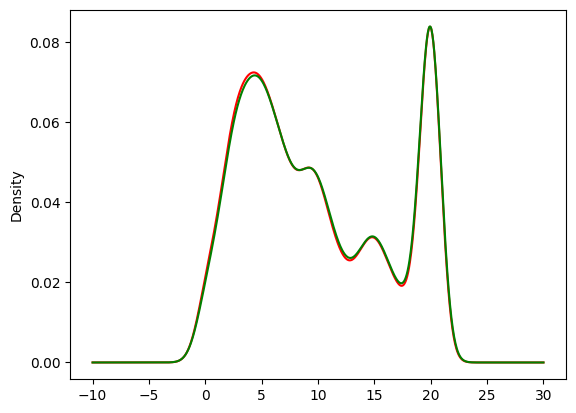

In [17]:
fig = plt.figure()
ax = fig.add_subplot(111)

# original data
df['experience'].plot.density(color='red')

# data after cca
new_df['experience'].plot.density(color='green')

## We can see that even after CCA, ratio of amount of data/total data is more or less the same for the below columns, so CCA can be applied!

In [18]:
temp = pd.concat([
            # percentage of observations per category, original data
            df['enrolled_university'].value_counts() / len(df),

            # percentage of observations per category, cca data
            new_df['enrolled_university'].value_counts() / len(new_df)
        ],
        axis=1)

# add column names
temp.columns = ['original', 'cca']

temp

,original,cca
enrolled_university,,
no_enrollment,0.721213,0.735188
Full time course,0.196106,0.200733
Part time course,0.062533,0.064079


In [19]:
temp = pd.concat([
            # percentage of observations per category, original data
            df['education_level'].value_counts() / len(df),

            # percentage of observations per category, cca data
            new_df['education_level'].value_counts() / len(new_df)
        ],
        axis=1)

# add column names
temp.columns = ['original', 'cca']

temp

,original,cca
education_level,,
Graduate,0.605387,0.619835
Masters,0.227633,0.234082
High School,0.105282,0.107380
Phd,0.021610,0.022116
Primary School,0.016077,0.016587


# Since we have NOT trained our model on any missing values, when the model is on production it will not be able to handle any missing values, if uploaded since it never encountered one while being trained